Dataset loaded successfully

--- Dataset shape ---
(6362620, 11)

--- First five records ---
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  

--- Column 

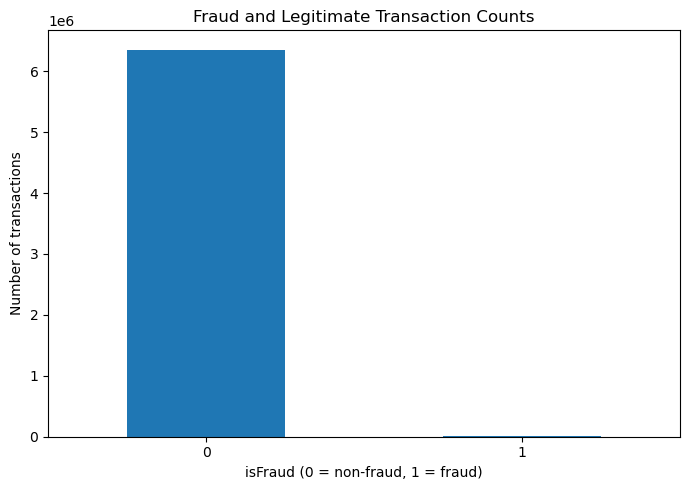

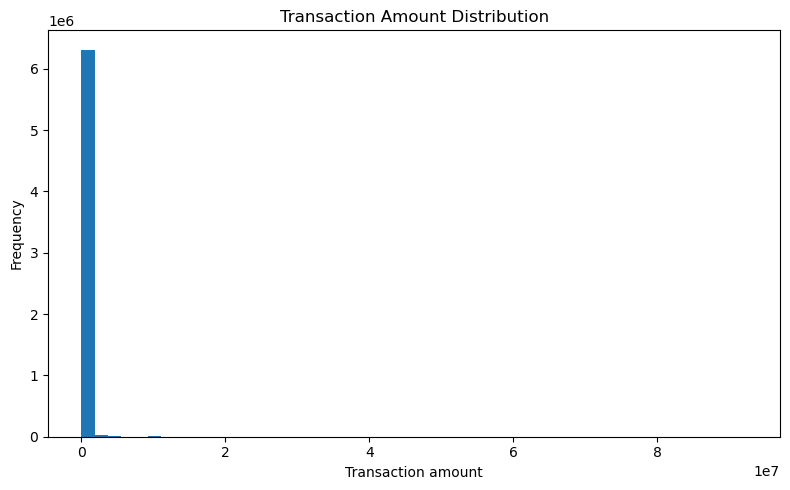

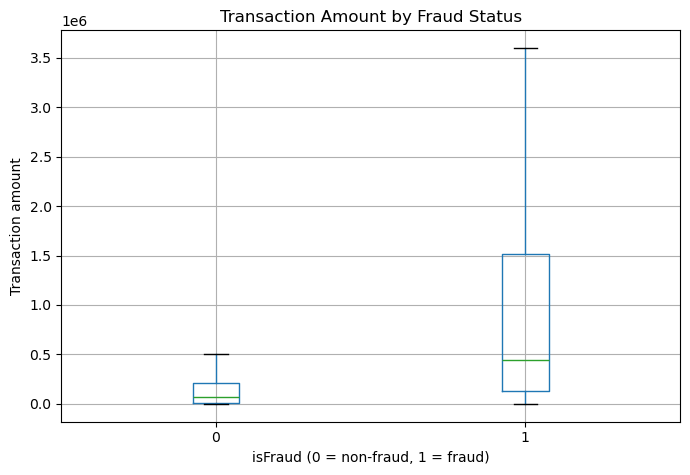

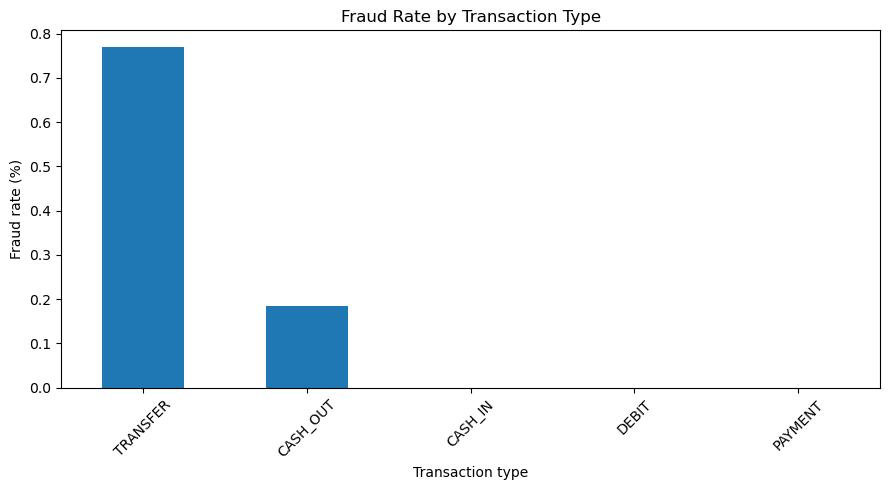

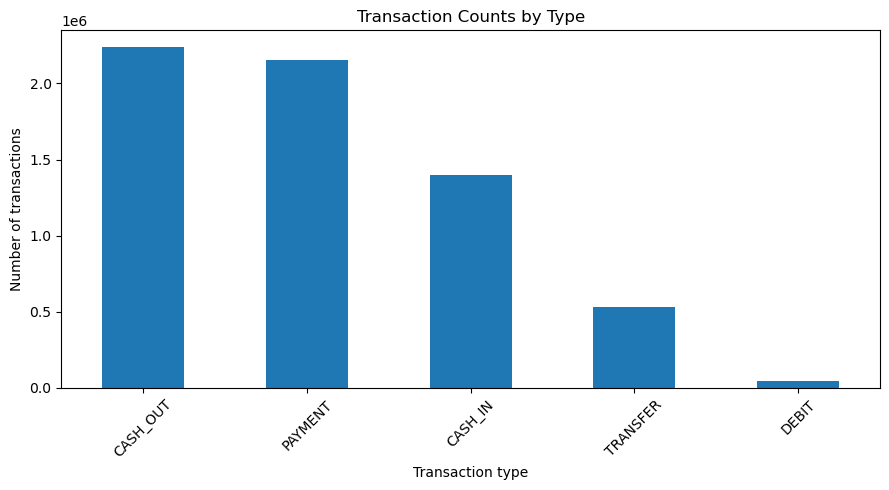

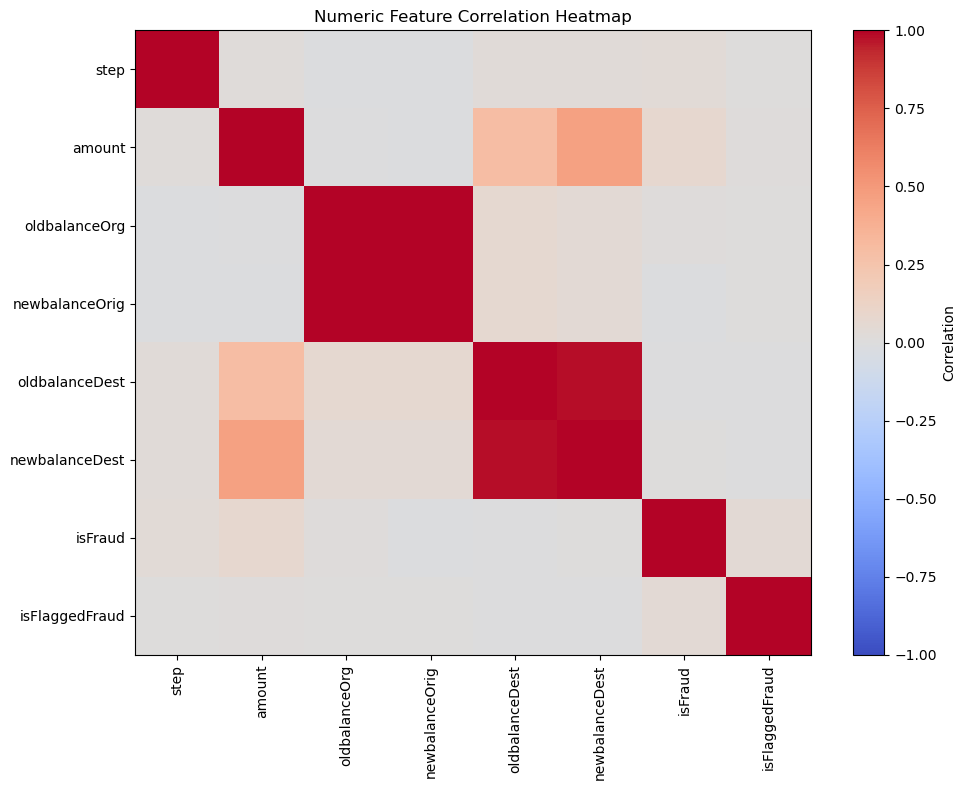


Target distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Training rows: 4453674
Validation rows: 954553
Testing rows: 954393

Training Baseline...

Training Logistic Regression...

Training Random Forest...

========== VALIDATION RESULTS ==========
              Model  Average Precision  Precision   Recall  F1 Score  Threshold
      Random Forest           0.945915   0.913644 0.858766  0.885356   0.250000
Logistic Regression           0.589285   0.828212 0.481331  0.608830   0.999752
           Baseline           0.001291   0.001291 1.000000  0.002578   0.001291

Selected model: Random Forest
Selected threshold: 0.25

========== FINAL TEST RESULTS ==========
Average Precision: 0.9417
ROC-AUC: 0.9946
Precision: 0.9069
Recall: 0.8539
F1 Score: 0.8796

Confusion Matrix:
[[953053    108]
 [   180   1052]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    953161
           1       0.91     

In [4]:
# ==========================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==========================================
from pathlib import Path
import importlib
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_auc_score
)

PROJECT_ROOT = Path.cwd()
sys.path.append(str(PROJECT_ROOT / "utils"))
import verify_dataset
importlib.reload(verify_dataset)

# ==========================================
# STEP 2: LOAD THE DATASET
# ==========================================
DATA_PATH = "data/payment_dataset.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully")

df = verify_dataset.inspect_data(
    Path("data/payment_dataset.csv")
)
print(df)

#============================================
# STEP 3: Data Engineering  EDP
#============================================
import bar_chart
import train_models
importlib.reload(bar_chart)
bar_chart.fraud_class_counts(
    df, filename="fraud_class_counts.png"
)
bar_chart.transaction_amount_distribution(
    df, filename="amount_distribution.png"
)

bar_chart.amount_by_fraud_status(
    df, filename="amount_by_fraud.png"
)

bar_chart.fraud_rate_by_type(
    df, filename="fraud_rate_by_type.png"
)

bar_chart.transaction_type_counts(
    df, filename="transaction_type_counts.png"
)

bar_chart.numeric_correlation_heatmap(
    df, filename="correlation_heatmap.png"
)

# ==========================================
# STEP 4: SELECT FEATURES AND TARGET
# ==========================================
NUMERIC_FEATURES = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

CATEGORICAL_FEATURES = ["type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "isFraud"

required_columns = FEATURES + [TARGET]
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

if df[TARGET].isna().any():
    raise ValueError("The target contains missing values.")

if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("isFraud must contain only 0 and 1.")

X = df[FEATURES].copy()
y = df[TARGET].astype(int)

print("\nTarget distribution:")
print(y.value_counts())

# ==========================================
# STEP 5: SPLIT THE DATA

# ==========================================
# 85% training, 15% testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)
# 70% training, 15% validation, 15% testing
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.1765,
    random_state=42,
    stratify=y_dev
)

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

# ==========================================
# STEP 6: PREPROCESS THE FEATURES
# ==========================================
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

# ==========================================
# STEP 7: DEFINE THE ML MODELS
# ==========================================
models = {
    "Baseline": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

# ==========================================
# STEP 8: TRAIN AND COMPARE MODELS
# ==========================================
results = []
trained_models = {}
validation_scores = {}

for name, estimator in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", estimator)
    ])

    pipeline.fit(X_train, y_train)

    # Predict fraud scores on validation data
    scores = pipeline.predict_proba(X_val)[:, 1]

    # Select threshold using validation data only:
    # choose the threshold with the highest F1-score.
    precision_curve, recall_curve, thresholds = (
        precision_recall_curve(y_val, scores)
    )

    if len(thresholds) > 0:
        f1_values = (
            2 * precision_curve[:-1] * recall_curve[:-1]
            / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
        )
        best_index = int(np.argmax(f1_values))
        threshold = float(thresholds[best_index])
    else:
        threshold = 0.5

    predictions = (scores >= threshold).astype(int)

    results.append({
        "Model": name,
        "Average Precision": average_precision_score(y_val, scores),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Threshold": threshold
    })

    trained_models[name] = pipeline
    validation_scores[name] = scores

# Display the validation comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Average Precision", ascending=False
).reset_index(drop=True)

print("\n========== VALIDATION RESULTS ==========")
print(results_df.to_string(index=False))

# ==========================================
# STEP 9: SELECT THE BEST MODEL
# ==========================================
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_threshold = float(results_df.loc[0, "Threshold"])

print("\nSelected model:", best_model_name)
print("Selected threshold:", best_threshold)

# ==========================================
# STEP 10: FINAL TEST EVALUATION
# ==========================================
# The test set was not used for model selection.
test_scores = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= best_threshold).astype(int)

print("\n========== FINAL TEST RESULTS ==========")
print(
    "Average Precision:",
    round(average_precision_score(y_test, test_scores), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_scores), 4)
)
print(
    "Precision:",
    round(precision_score(y_test, test_predictions, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, test_predictions, zero_division=0), 4)
)
print(
    "F1 Score:",
    round(f1_score(y_test, test_predictions, zero_division=0), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))

# ==========================================
# STEP 11: SAVE THE MODEL AND RESULTS
# ==========================================
Path("artifacts").mkdir(parents=True, exist_ok=True)
# Check whether best_model exists
print("Best model:", best_model)

# Save the trained model
joblib.dump(
    best_model,
    "artifacts/best_ml_model.joblib"
)

results_df.to_csv(
    "artifacts/ml_validation_comparison.csv",
    index=False
)

pd.DataFrame({
    "actual": y_test.to_numpy(),
    "fraud_score": test_scores,
    "predicted": test_predictions
}).to_csv(
    "artifacts/ml_test_predictions.csv",
    index=False
)

print("\nSaved:")
print("artifacts/best_ml_model.joblib")
print("artifacts/ml_validation_comparison.csv")
print("artifacts/ml_test_predictions.csv")

print(results_df)
print("Selected model:", best_model_name)
print("Selected threshold:", best_threshold)
#========================================================
### Step 12: Validation
#========================================================
from pathlib import Path

Path("tests").mkdir(parents=True, exist_ok=True)

test_code = '''
import numpy as np
import pandas as pd
import pytest
from pathlib import Path

from src_validation import (
    select_best_threshold,
    evaluate_validation,
    select_best_model
)

# 1
def test_threshold_range():
    y = np.array([0, 0, 1, 1])
    scores = np.array([0.1, 0.2, 0.8, 0.9])
    threshold = select_best_threshold(y, scores)
    assert 0 <= threshold <= 1

# 2
def test_threshold_is_float():
    y = np.array([0, 1, 0, 1])
    scores = np.array([0.1, 0.9, 0.2, 0.8])
    assert isinstance(select_best_threshold(y, scores), float)

# 3
def test_validation_returns_metrics():
    y = np.array([0, 1, 0, 1])
    scores = np.array([0.1, 0.9, 0.2, 0.8])
    result = evaluate_validation(y, scores, 0.5)
    assert "Average Precision" in result

# 4
def test_precision_exists():
    y = np.array([0, 1, 0, 1])
    scores = np.array([0.1, 0.9, 0.2, 0.8])
    result = evaluate_validation(y, scores, 0.5)
    assert "Precision" in result

# 5
def test_recall_exists():
    y = np.array([0, 1, 0, 1])
    scores = np.array([0.1, 0.9, 0.2, 0.8])
    result = evaluate_validation(y, scores, 0.5)
    assert "Recall" in result

# 6
def test_f1_exists():
    y = np.array([0, 1, 0, 1])
    scores = np.array([0.1, 0.9, 0.2, 0.8])
    result = evaluate_validation(y, scores, 0.5)
    assert "F1 Score" in result

# 7
def test_metrics_between_zero_and_one():
    y = np.array([0, 1, 0, 1])
    scores = np.array([0.1, 0.9, 0.2, 0.8])
    result = evaluate_validation(y, scores, 0.5)
    assert all(0 <= v <= 1 for v in result.values())

# 8
def test_best_model_selected():
    data = pd.DataFrame({
        "Model": ["LR", "RF"],
        "Average Precision": [0.7, 0.9]
    })
    assert select_best_model(data)["Model"] == "RF"

# 9
def test_empty_results_rejected():
    data = pd.DataFrame(columns=["Model", "Average Precision"])
    with pytest.raises(ValueError):
        select_best_model(data)

# 10
def test_best_model_not_worse_than_other():
    data = pd.DataFrame({
        "Model": ["A", "B", "C"],
        "Average Precision": [0.6, 0.8, 0.7]
    })
    assert select_best_model(data)["Average Precision"] == 0.8

# 11
def test_model_file_exists():
    assert Path("artifacts/best_ml_model.joblib").exists()

# 12
def test_validation_results_file_exists():
    assert Path("artifacts/ml_validation_comparison.csv").exists()

# 13
def test_test_predictions_file_exists():
    assert Path("artifacts/ml_test_predictions.csv").exists()
'''

Path("tests/test_project.py").write_text(test_code, encoding="utf-8")

print("Test file created successfully.")